# Debenture liquidity provider: model, robustness, scaling and live test

**One notebook with everything:** the strategy, every model we tested and what we learned, the robustness analysis, how to scale, and exactly what data to pull from SQL to test it live.

| | |
|---|---|
| **Strategy** | When someone **dumps** a debenture (a trade ≥ R$ 300k at ≥ 50 bps below its fair value), be the **buyer**. A walk-forward model picks which dumps to buy. Sell at the next real trade after 21 business days. Hedge the rates part of IPCA+ / pre-fixed bonds with Tesouro. Idle cash earns CDI. |
| **Result** (out of sample 2024-01 → 2026-10, 1 bp per side, R$ 50 mi, 20% capture) | ≈ **CDI + 7%/yr**, Sharpe ≈ 1.9, worst month ≈ −3% (one-sided risk limit in distressed names). Benchmarks: CDI 12.6%/yr; passive CDI+ debentures 14.5%/yr. |
| **Robust?** | **The sign is robust:** CDI + positive in all ~60 variants, robust to cost up to 10 bp, look-ahead lag, seeds and limits. **The size is not:** it depends on fund size, lot size and holding period, and the edge fell to ≈ CDI + 2% from mid-2025 (§ 9). |
| **Scales to** | ≈ R$ 400 mi of inventory at 20% capture, ≈ R$ 1 bn at 50%. Flow is the constraint, not capital (§ 10). |

**How to use it**
1. Set the data sources in § 3 (`SOURCE = "sql"` for the internal tables, `"file"` for the local cache).
2. Run all cells. A full run takes about 10 minutes; set `RUN_FULL_ROBUSTNESS = False` to skip the slow rebuilds.
3. For a live / paper test, follow § 11-12. They give a daily bid sheet, an RFQ scorer and a trade log.

Contents:
1. Manual: what the strategy does, step by step
2. Everything we tested (models, results, verdicts, files)
3. Config
4. Data: what we get and from where (SQL vs download)
5. Build the dataset
6. Model (walk-forward)
7. Book simulation
8. Backtest and equity curve
9. Robustness analysis
10. Scaling: capacity, block sleeve, fund size × capture
11. Live test: data to pull from SQL, daily routine, pre-registered go/no-go criteria
12. Live tools: final model, daily bid sheet, RFQ scorer, paper-trade log

## 1. Manual: what the strategy does, step by step

**Why it makes money.**
- Debentures are illiquid. A seller who must sell **now** (redemptions in a fund, a risk limit, a dealer who won't carry inventory overnight) accepts a price below fair value.
- Whoever is on the other side of that trade earns the discount when the price returns to fair.
- That is the dealer's spread. Being that buyer is the edge.
- Buying **after** seeing the cheap trade (next day) loses money (−15 bps per trade), so the edge exists only for the **counterparty**.

**Step by step**
1. **Fair value** of each bond = yesterday's ANBIMA %PU par (known before any of today's trades).
2. **Dump** = a trade ≥ R$ 300k whose %PU par is 50-2000 bps below that fair value.
3. **Model**: LightGBM gives P(this dump earns money after 21 bd, rates-hedged). It is trained each quarter only on dumps whose exit had already happened, then calibrated (isotonic) on earlier out-of-sample quarters.
   - Features: discount, size, size / ADV, duration, price level, mark momentum (bond and issuer), issuer's worst bond, days since last trade, time of day, how many dumps the bond had earlier that day, round lot, SND payment failures, days since a credit-fund stress episode began.
4. **Decision**: buy if P ≥ 0.70 and there is no SND payment failure in the bond or issuer in the last 90 days.
5. **Size** = min(dump size, 4% of capital per bond (1% if the bond or the issuer's worst bond is < 90% of par), 15% per issuer, free capital). Only 20% of dumps are assumed to reach the desk (random).
6. **Exit**: sell at the daily VWAP of the first trade day after t + 21 bd. Windows with a scheduled SND cash event are skipped.
7. **Hedge**: IPCA+ and PRE positions carry a short duration-matched Tesouro position, sized by a **walk-forward beta**. IPCA+ debentures stopped following the NTN-B in 2026 (beta 0.9 → 0.3), so a full hedge lost money.
8. **Cash** not in positions earns CDI. Cost: 1 bp per side (the desk's figure). The measured dealer markup is also reported in § 9.

**P&L convention.** Return = PU_exit / PU_entry − CDI over the period − hedge leg − 2 × cost, where the PU change reflects the %PU par change and par accrual. Windows containing cash events are dropped, so coupons and amortization never enter the return.

## 2. Everything we tested

Each line is a model or hypothesis that was actually run. Code lives in `src/` and results in `reports/`. Full ledgers: `reports/RESEARCH_NOTES.md` (rounds 1-10), `reports/research/LAB_LEDGER.md` (rounds 11-14), `reports/STRATEGY_FINAL.md`, `reports/SENSITIVITY_simple_model.md`.

### 2.1 Costs and fair value (rounds 1-5)
| Model | What it does | Result | Verdict | File |
|---|---|---|---|---|
| Dealer back-to-back pairs | Two trades with the same quantity within minutes = a dealer passing a bond through; markup = price difference | Round-trip markup by size: < R$ 100k ≈ 178 bps, 100-300k ≈ 146, **300k-1 mi ≈ 60 (median 1)**, 1-3 mi ≈ 20, 3-10 mi ≈ 10, > 10 mi ≈ 7 | Basis of the cost table (`results_costs.json`) | `src/costs.py` |
| Pair initiator | Which leg came first = who started the trade (buy vs sell flow) | Leg sides always balance; only the initiator carries flow information | Feature `sell20` | `src/costs.py` |
| Kalman fair spread | Student-t Kalman filter on prints + marks | Works as a fair value **only with the prior state**. The posterior made fake 83-90% precision (filter lag) | Used in the full pipeline; the simple notebook uses yesterday's ANBIMA mark | `src/kalman.py` |
| Issuer-curve relative value | WLS + issuer random effects; cheap vs the issuer's own curve | +6 to +12 bps per 21 d net when trading anyway; monthly exclusion of the worst decile +0.6-0.8%/yr | Core-book overlay | `src/curve_rv.py`, `target_lab*.py` |
| Execution | Hawkes, optimal stopping, Almgren-Chriss; wait for a cheap print with a deadline | +7 to +16 bps per purchase | Execution rule | `src/exec_opt.py` |
| Hazard / Merton DD / fire-sale network / QP holdings | Default hazard, distance-to-default, contagion via common holders | Monthly drop AUC ≈ 0.75, not tradeable on its own | Filters only | `src/hazard.py`, `firesale.py` |

### 2.2 Predicting price direction (rounds 6-9, 11)
| Model | Result | Verdict |
|---|---|---|
| T2 issuer/indexer-neutral target (21 d) | IC 0.075 on tradeable returns; avoid-rule +0.6-0.8%/yr | Core overlay only |
| Daily mark drop model (5 / 10 / 20 / 40 d), with propagation across indexers via the Tesouro curve | 70-79% precision the same day, **45-54% with a 1-day lag** | **Artifact.** The ANBIMA mark needs ~3 days to absorb news (0.5 × dealer quotes 3-day avg + 0.35 / 0.10 / 0.05 trades). It forecasts the mark catching up with trades. |
| Credit-only "+" drop model v1-v3 (honest labels, causal spike cleaning) | Same lag problem; useful as a **tail-insurance** sell signal: 47 alarms / yr, 52% hit, mean +146 bps, median +6 → +0.7% NAV / yr | Insurance, not alpha |
| Rise model + trading strategy (target CDI + 10%) | Weak; hit rate inflated by "lucky-print" exits; CDI + 10% unreachable | Dead |
| Inflation vs Focus (to forecast IPCA better than the market) | No edge | Dead |
| New-issue premium (buy in the primary offer) | −22 to −31 bps median vs CDI | Avoid the primary |
| Cross-sectional LightGBM with all research features, executable labels | IC 0.03-0.05; loses at measured cost | Dead: direction of the universe is not tradeable |
| Equity residual (issuer stock vs IBOV) leads credit | t = 2.7 at 10 d, 8-30 bps | Real but below cost alone |
| Issuer's most-traded bond leads its other bonds | +61 bps gross, negative net median | Dead net |
| Distress events (restructuring adviser, CFO exit, equity crash, rating) | Net median ≈ −cost; famous cases do not generalise | Dead (equity crash on bonds 85-97: insurance only) |
| Option-implied vol of issuer (B3 COTAHIST) | High IV −31 bps / 20 d (t −1.9); as a filter neutral in the book | Weak |
| FI-Infra listed funds price / premium to NAV | No lead either way | Dead |

### 2.3 Liquidity provision (rounds 10-14): the strategy that works
| Model | Result | Verdict |
|---|---|---|
| Counterparty to every dump ≥ R$ 300k, ≥ 50 bps below fair, 21 d, hedged | +108 bps / trade, 76% hit (CDI+ −19 before filters) | **The edge** |
| Next-day entry | −15 bps | The edge needs being the counterparty |
| Toxicity model (forced vs informed seller), LightGBM walk-forward | p ≥ 0.8: 79% hit, +126 bps; passes the t−2 lag test; book CDI + 7.7%/yr at 1 bp | Kept |
| CDI+ rule (bond ≥ 97% par, issuer worst ≥ 92%; fixed on 2023-24) + CDI-only model | Test 2025-26: 82% hit at p ≥ 0.8 | Kept (full pipeline) |
| Stress-cycle pause (no bids in the first 20 bd after CDI credit funds lose to CDI and bleed redemptions) | First 20 bd +29 bps vs +139 at 40-60 bd; worst month −2.0% → −1.3% | Kept |
| Walk-forward beta hedge | 2026 IPCA+ trades +41 → +90 bps; Sep/26 −271 → +75 | Kept |
| **Idea 12: late-day desperation** (dumps after 16:00 revert more, morning less) | +21 bps (t 4.6), morning −16 (t −3.4), mainly IPCA+ 16-17 h; alone +5.8%/yr (too few trades) | Kept as a feature (`hour`) |
| 20 original ideas (issuer buyback, performance-fee pump, iceberg, underwriter overhang, liquidating funds, coupon recycling, call pull, retail phase, covenant cliff, quarter end, holiday eve, round rate, name / auditor twins, manager bad day, weekday, rating birthday, supply fatigue, rain) | Only late-day survived \|t\| > 3 | `src/ideas20.py`, `ideas20_sig.py` |
| 10 Hail Marys | **Reversed and significant:** repeated same-day dumping is informed (t −5.2), odd lots informed (t −3.3), dump after ≥ 20 bd of silence = news (−74 bps) | `n_prior_today` and `round_lot` are features. "Last dump of the day" was look-ahead and was removed. |
| Final: every idea in one walk-forward model | CDI + 7.1%, Sharpe 2.7; base model only + 7.2; **buy every dump + 6.7; random selection + 6.7**; deflated Sharpe 0.64 (150 trials) | The money is in being the counterparty; the model adds ≈ +0.5%/yr |
| Ablation (drop one data group) | All 7.3%; only the print 7.1%; each other group −0.3 to −0.5 pp | Essentials = tape + fair value + hedge + CDI |

### 2.4 Look-ahead traps we found (and how to avoid them)
| Trap | What happened | Rule now |
|---|---|---|
| Kalman posterior | Used the print to judge the print: fake 83-90% | Fair value = state **before** the print |
| Bid-ask bounce | Last print vs next print: fake 80-91% | Signal price ≠ outcome price; entry/exit at the **next real trade** |
| Mark catch-up | Same-day mark models 70-79% → 45-54% lagged | Every signal gets a 1-day lag test |
| Spike cleaning using t+1 | Look-ahead | Causal median of past marks only |
| Centered windows in the taxa reconstruction | Look-ahead | Dropped |
| "Lucky print" exits | Choosing a good exit print inflated the hit rate | Exit = first trade day after t + h |
| "Last dump of the day", same-day IBOV, "sister series at fair today", "fund later liquidated" | Need the rest of the day / the future | Removed; only what is known at the print |
| Hand-picking ideas after seeing results | Round 14 reached Sharpe 3.2 in-sample | All ideas go in one walk-forward model |
| Full-duration rates hedge | The IPCA+ "+" looked like it widened when NTN-B rallied | Walk-forward beta |
| 20% capture is order-dependent | ±1%/yr from which dumps are drawn | Always average 10-30 random draws |

## 3. Config

**Data source.** Each dataset comes from `"sql"` (internal tables, via the helper `sql_func.try_retry(query)` → DataFrame) or `"file"` (local cache built by the scrapers / public downloads in `data/clean`). Queries are always date-limited, one month at a time.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path(r"C:\Users\maxpn\OneDrive\Documents\itau\credit-backtest")
CLEAN = ROOT / "data" / "clean"                 # local cache of collected / scraped data
OUT = ROOT / "simple_model_out"; OUT.mkdir(exist_ok=True)

SOURCE = {"trades": "file",                     # "sql": B3_CREDITO_OPERACOES  | "file": collected B3 tape
          "anbima": "file"}                     # "sql": tbhh3003_anbima_...    | "file": scraped ANBIMA marks
SQL = {
    "func_dir": os.environ.get("SQL_FUNC_DIR", str(ROOT)),           # folder with sql_func.py (try_retry)
    "trades_table": "B3_CREDITO_OPERACOES",
    "trades_cols": {"date": "datanegocio", "time": "horanegocio",    # "time": None if the table has no time column
                    "code": "codigoif", "type": "instrumentofinanceiro", "qty": "qtdadenegociada", "pu": "preconegocio",
                    "vol": "volumefinanceiro", "rate": "taxanegocio"},
    "trades_types": ("DEB",),                   # scaling test: ("DEB", "CRI", "CRA") - needs marks for those too
    "anbima_table": "tbhh3003_anbima_debenture_mercado_secundario",
    "anbima_cols": {"date": "data_referencia", "code": "codigo_ativo", "rate": "taxa_indicativa", "pu": "pu",
                    "pct_par": "percent_pu_par", "duration": "duration"},     # duration in business days
}

# --- strategy parameters (defaults = the backtested model)
START, OOS_START = "2023-04-01", "2024-01-01"   # tape starts 04/2023; model out of sample from 2024
MIN_VOL, MIN_DISC, MAX_DISC = 3e5, 50, 2000     # dump = >= R$ 300k at 50-2000 bps (price) below fair
HOLD_BD, COST_BPS, LAG_BD = 21, 1.0, 1          # hold; cost per side (bps); fair value from t - LAG_BD
CAPITAL, CAPTURE, CUT = 50e6, 0.20, 0.70        # fund size; share of dumps that reach the desk; buy if p >= CUT
CAP_BOND, CAP_ISSUER = 0.04, 0.15               # max share of capital per bond / issuer
DISTRESS_PCT, CAP_DISTRESS = 90, 0.01           # bond or issuer worst bond < 90% of par -> max 1% per bond
BLOCK_MIN, CAP_BLOCK = 3e6, None                # scaling: dumps >= BLOCK_MIN get CAP_BLOCK (None = same as CAP_BOND)
N_DRAWS = 10                                    # random capture draws per result
USE_FUND_STRESS = True                          # CVM credit-fund stress feature (data/clean/credit_fund_agg.parquet)
RUN_FULL_ROBUSTNESS = True                      # False skips the slow rebuilds in section 9
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=200, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.7, reg_lambda=10.0, random_state=0, verbose=-1)
FEATS = ["disc", "log_vol", "size_adv", "dur", "fair", "is_cdi", "is_ipca", "is_pre", "days_since", "mom5", "mom20",
         "iss_mom5", "iss_min", "fail_bond90", "fail_iss90", "hour", "n_prior_today", "round_lot", "dse"]

## 4. Data: what we get and from where

| # | Data | Used for | Source today | From SQL? | Importance |
|---|---|---|---|---|---|
| 1 | **B3 debenture trades** (date, **time**, code, qty, PU, R$ volume, rate) | Dumps, entry price, size, time of day, exit price, ADV, days since last trade | Collected B3 tape (`trades_b3.parquet`) | **Yes: `B3_CREDITO_OPERACOES`**. Check that a time column exists (`horanegocio`?) and how cancelled trades are flagged | Essential |
| 2 | **ANBIMA marks** (taxa indicativa, PU, %PU par, duration) | Fair value, duration, level, momentum | Scraped ANBIMA page (live bonds only) + SND | **Yes: `tbhh3003_anbima_debenture_mercado_secundario`** (all bonds, incl. dead ones → no survivorship) | Essential |
| 3 | Bond characteristics (indexer, issuer CNPJ, spread / coupon, dates, call clause) | Hedge type, issuer limits, benchmark | SND download (debentures.com.br) | If there is an internal bond master, use it | Essential |
| 4 | SND events (coupons, amortizations, early redemptions, **payment failures**) | Skip cash-event windows; no buys after a default | SND "PU de eventos" | If available internally | Essential |
| 5 | Tesouro curve (pre and IPCA+) | Rates hedge | Tesouro Transparente CSV | Internal curves (or DI1 / DAP futures) are better | Essential for IPCA+ / PRE |
| 6 | CDI, IPCA | Cash, benchmark, hedge carry | BCB SGS API | Either | Essential |
| 7 | Credit-fund stress (CVM informe diário + CDA) | Strongest extra feature (`dse`) | CVM open data (built by `src/regime_lab.py`) | Internal positions table helps for own funds | Optional (+) |

In [2]:
def _sql(query):
    sys.path.insert(0, SQL["func_dir"])
    from sql_func import try_retry                       # user's helper: try_retry(query) -> DataFrame
    df = try_retry(query)
    df = df if isinstance(df, pd.DataFrame) else pd.DataFrame(df)
    df.columns = [str(c).lower() for c in df.columns]
    return df

def _sql_by_month(build_query):
    """date-limited: one query per month."""
    return pd.concat([_sql(build_query(m.start_time.strftime("%Y-%m-%d"), m.end_time.strftime("%Y-%m-%d")))
                      for m in pd.period_range(START, pd.Timestamp.today(), freq="M")], ignore_index=True)

def load_trades():
    """B3 DEBENTURE TRADES - every secondary trade. returns date, time ('HH:MM:SS' or None), code, qty, pu, vol, rate"""
    if SOURCE["trades"] == "sql":
        c = SQL["trades_cols"]; cols = [v for v in c.values() if v]
        types = ",".join(f"'{t}'" for t in SQL["trades_types"])
        T = _sql_by_month(lambda a, b: f"SELECT {', '.join(cols)} FROM {SQL['trades_table']} WHERE {c['date']} >= '{a}' "
                                       f"AND {c['date']} <= '{b}' AND {c['type']} IN ({types})")
        T = T.rename(columns={v.lower(): k for k, v in c.items() if v})
        if "time" not in T: T["time"] = None
    else:
        T = pd.read_parquet(CLEAN / "trades_b3.parquet", columns=["date", "time", "code", "qty", "pu", "vol", "rate"])
    T["date"] = pd.to_datetime(T.date).dt.normalize()
    T["code"] = T.code.astype(str).str.strip().str.upper()
    for k in ("qty", "pu", "vol", "rate"): T[k] = pd.to_numeric(T[k], errors="coerce")
    return T[(T.pu > 0) & (T.vol > 0) & (T.date >= START)].drop_duplicates(["date", "time", "code", "qty", "pu"]).reset_index(drop=True)

def load_anbima():
    """ANBIMA DAILY MARKS. returns date, code, pct_par (% of PU par), pu_par (R$), dur (years)"""
    if SOURCE["anbima"] == "sql":
        c = SQL["anbima_cols"]
        A = _sql_by_month(lambda a, b: f"SELECT {', '.join(c.values())} FROM {SQL['anbima_table']} "
                                       f"WHERE {c['date']} >= '{a}' AND {c['date']} <= '{b}'")
        A = A.rename(columns={v.lower(): k for k, v in c.items()})
        A["pct_par"] = pd.to_numeric(A.pct_par, errors="coerce")
        A["pu_par"] = pd.to_numeric(A.pu, errors="coerce") / (A.pct_par / 100)
        A["dur"] = pd.to_numeric(A.duration, errors="coerce") / 252
    else:
        A = pd.read_parquet(CLEAN / "bond_daily.parquet", columns=["code", "date", "anbima_pct", "anb_par"]).dropna()
        A = A.rename(columns={"anbima_pct": "pct_par", "anb_par": "pu_par"})
        A = A.merge(pd.read_parquet(CLEAN / "duration_exact.parquet").rename(columns={"dur_exact": "dur"}), on=["code", "date"], how="left")
    A["date"] = pd.to_datetime(A.date).dt.normalize()
    A["code"] = A.code.astype(str).str.strip().str.upper()
    A = A[(A.pct_par > 1) & (A.pu_par > 0)].drop_duplicates(["code", "date"]).sort_values(["code", "date"])
    A["dur"] = A.groupby("code").dur.ffill()
    return A[["date", "code", "pct_par", "pu_par", "dur"]].reset_index(drop=True)

def load_bonds():
    """BOND CHARACTERISTICS (SND). returns index=code: indexer, root (issuer CNPJ root), spread"""
    B = pd.read_parquet(CLEAN / "bonds.parquet").drop_duplicates("code").set_index("code")
    B["root"] = B.issuer_cnpj.astype(str).str.replace(r"\D", "", regex=True).str.zfill(14).str[:8]
    B["spread"] = pd.to_numeric(B.coupon, errors="coerce")
    return B[["indexer", "root", "spread"]]

def load_events():
    """SND EVENTS (payments, failures). returns code, date, failed"""
    E = pd.read_parquet(CLEAN / "snd_events.parquet", columns=["code", "date", "failed", "status"])
    E["failed"] = E.failed.fillna(False).astype(bool) & ~E.status.astype(str).str.contains("ATRAV", na=False)
    return E[["code", "date", "failed"]]

def load_tesouro():
    """TESOURO DIRETO RATES (free CSV). returns {"PRE"|"IPCA+": {date: (maturity_years, rate %)}}"""
    f = ROOT / "data" / "raw" / "alt" / "tesouro" / "td.csv"
    if not f.exists():
        import requests
        url = ("https://www.tesourotransparente.gov.br/ckan/dataset/df56aa42-484a-4a59-8184-7676580c81e3/resource/"
               "796d2059-14e9-44e3-80c9-2d9e30b405c1/download/PrecoTaxaTesouroDireto.csv")
        f.parent.mkdir(parents=True, exist_ok=True); f.write_bytes(requests.get(url, timeout=300).content)
    d = pd.read_csv(f, sep=";", decimal=",")
    d["date"] = pd.to_datetime(d["Data Base"], dayfirst=True)
    d["T"] = (pd.to_datetime(d["Data Vencimento"], dayfirst=True) - d.date).dt.days / 365.25
    d["rate"] = d["Taxa Venda Manha"].where(d["Taxa Venda Manha"] > 0)
    d = d.dropna(subset=["rate"]); d = d[d.date >= pd.Timestamp(START) - pd.Timedelta(days=30)]
    return {k: {dt: (x.sort_values("T")["T"].values, x.sort_values("T").rate.values) for dt, x in d[d["Tipo Titulo"] == n].groupby("date")}
            for k, n in (("PRE", "Tesouro Prefixado"), ("IPCA+", "Tesouro IPCA+"))}

def _sgs(code, cache):
    f = CLEAN / cache
    if f.exists(): return pd.read_parquet(f)
    import requests
    s = pd.DataFrame(requests.get(f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{code}/dados?formato=json&dataInicial=01/01/2022", timeout=120).json())
    s["date"] = pd.to_datetime(s.data, dayfirst=True); s["value"] = s.valor.astype(float)
    s[["date", "value"]].to_parquet(f); return s[["date", "value"]]

def load_cdi():
    """CDI (BCB SGS 12). returns cumulative index on business days"""
    c = pd.read_parquet(CLEAN / "cdi.parquet").set_index("date").cdi / 100 if (CLEAN / "cdi.parquet").exists() else _sgs(12, "sgs12.parquet").set_index("date").value / 100
    idx = (1 + c).cumprod()
    return idx.reindex(pd.bdate_range(idx.index.min(), idx.index.max())).ffill()

def load_ipca():
    """IPCA monthly (BCB SGS 433). returns Series by month"""
    s = _sgs(433, "sgs433.parquet"); return pd.Series(s.value.values / 100, index=s.date.dt.to_period("M"))

def load_fund_stress():
    """CREDIT-FUND STRESS start dates (CVM; public +7 d): CDI credit funds lose to CDI over 21 d AND net redemptions 21 d."""
    f = CLEAN / "credit_fund_agg.parquet"
    if not USE_FUND_STRESS or not f.exists(): return None
    A = pd.read_parquet(f).reset_index()[["known", "xr21", "fl21"]].sort_values("known")
    starts, last = [], None
    for d, v in zip(A.known, (A.xr21 < 0) & (A.fl21 < 0)):
        if v and (last is None or (d - last).days > 90): starts.append(d)
        if v: last = d
    return pd.Series(pd.to_datetime(starts))

t0 = time.time()
DATA = dict(T=load_trades(), A=load_anbima(), B=load_bonds(), E=load_events(), CDI=load_cdi(), C=load_tesouro(),
            ipca=load_ipca(), stress=load_fund_stress())
CDI = DATA["CDI"]
print({k: (len(v) if hasattr(v, "__len__") else v) for k, v in DATA.items()}, f"{time.time() - t0:.0f}s")
print("trades:", DATA["T"].date.min().date(), "->", DATA["T"].date.max().date(), "| time column present:", DATA["T"].time.notna().mean().round(3))

{'T': 5691867, 'A': 842430, 'B': 9998, 'E': 132205, 'CDI': 2300, 'C': 2, 'ipca': 57, 'stress': 5} 8s
trades: 2023-04-03 -> 2026-10-26 | time column present: 1.0


## 5. Build the dataset

`build()` finds every dump, computes its outcome (exit, CDI, hedge leg) and its features. Everything is known at the moment of the print: marks are from t − `LAG_BD`; time, size and the dump count are from the print itself. The dump filter is applied loosely here (≥ R$ 100k, 30-5000 bps) so that § 9 can vary it without rebuilding. `dumps()` then applies the configured filter.

In [3]:
def curve_at(C, kind, dates, durs):
    keys = np.array(sorted(C[kind]), dtype="datetime64[ns]")
    idx = np.searchsorted(keys, np.asarray(dates, dtype="datetime64[ns]"), side="right") - 1
    out = np.full(len(idx), np.nan)
    for i, (j, d) in enumerate(zip(idx, durs)):
        if j >= 0 and np.isfinite(d):
            Tm, r = C[kind][pd.Timestamp(keys[j])]; out[i] = np.interp(d, Tm, r) / 100
    return out

def build(hold_bd=HOLD_BD, lag_bd=LAG_BD, min_vol=1e5, min_disc=30, max_disc=5000, cost_bps=COST_BPS):
    T, A, B, E = DATA["T"].copy(), DATA["A"].copy(), DATA["B"], DATA["E"]
    C, ipca, stress = DATA["C"], DATA["ipca"], DATA["stress"]
    T["indexer"], T["root"] = T.code.map(B.indexer), T.code.map(B.root)
    T = T[T.indexer.isin(["CDI+", "%CDI", "IPCA+", "PRE"])]
    Dly = T.assign(pv=T.pu * T.vol).groupby(["code", "date"]).agg(pv=("pv", "sum"), vol=("vol", "sum")).reset_index()
    Dly["pu_vwap"] = Dly.pv / Dly.vol
    # dumps: print %PU par vs yesterday's ANBIMA %PU par
    P = T[T.vol >= min_vol].merge(A[["code", "date", "pu_par"]], on=["code", "date"], how="left")
    P["pct"] = P.pu / P.pu_par * 100
    P["tm1"] = P.date - pd.offsets.BDay(lag_bd)
    A1 = A.rename(columns={"date": "tm1", "pct_par": "fair"})[["code", "tm1", "fair", "dur"]]
    P = pd.merge_asof(P.sort_values("tm1"), A1.sort_values("tm1"), on="tm1", by="code", direction="backward", tolerance=pd.Timedelta(days=7))
    P["disc"] = (P.fair - P.pct) / P.fair * 1e4
    P = P[P.disc.between(min_disc, max_disc)].copy()
    # outcome: exit at the daily VWAP of the first trade day after t + hold_bd; skip windows with SND cash events
    days = {k: (g.date.values, g.pu_vwap.values) for k, g in Dly.groupby("code")}
    evs = {k: np.sort(g.date.values) for k, g in E.groupby("code")}
    te, pu_out = [], []
    for code_, t in zip(P.code.values, P.date.values):
        d, pu = days.get(code_, (np.array([], "datetime64[ns]"), None))
        tgt = np.datetime64(pd.Timestamp(t) + pd.offsets.BDay(hold_bd))
        j = np.searchsorted(d, tgt, side="right")
        ok = j < len(d) and d[j] <= tgt + np.timedelta64(14, "D")
        if ok and code_ in evs:
            e = evs[code_]; k = np.searchsorted(e, t, side="right"); ok = not (k < len(e) and e[k] <= d[j])
        te.append(d[j] if ok else np.datetime64("NaT")); pu_out.append(pu[j] if ok else np.nan)
    P["te"], P["pu_out"] = pd.to_datetime(te), pu_out
    P = P.dropna(subset=["te"]).copy()
    P["ex"] = P.pu_out / P.pu - P.te.map(CDI).values / P.date.map(CDI).values - 2 * cost_bps / 1e4
    # rates hedge leg (IPCA+ / PRE): Tesouro excess over CDI (carry + inflation + price)
    P["tes"] = 0.0
    for k in ("PRE", "IPCA+"):
        m = (P.indexer == k) & P.dur.notna()
        y0 = curve_at(C, k, P.loc[m, "date"].values, P.loc[m, "dur"].values)
        y1 = curve_at(C, k, P.loc[m, "te"].values, P.loc[m, "dur"].values)
        bd = np.busday_count(P.loc[m, "date"].values.astype("datetime64[D]"), P.loc[m, "te"].values.astype("datetime64[D]"))
        infl = np.ones(m.sum())
        if k == "IPCA+":
            infl = np.array([(1 + ipca.get(a, ipca.iloc[-1])) ** (b_ / 21) for a, b_ in zip(P.loc[m, "date"].dt.to_period("M"), bd)])
        cdi_acc = P.loc[m, "te"].map(CDI).values / P.loc[m, "date"].map(CDI).values
        P.loc[m, "tes"] = (1 + y0) ** (bd / 252) * infl - cdi_acc - P.loc[m, "dur"].values * (y1 - y0)
    P = P.dropna(subset=["tes"])
    P["beta"] = 1.0                                     # walk-forward hedge ratio from trades closed in the prior 12 months
    for k in ("PRE", "IPCA+"):
        for q in pd.period_range(P.date.min(), P.date.max(), freq="Q"):
            past = P[(P.indexer == k) & (P.te < q.start_time) & (P.te >= q.start_time - pd.Timedelta(days=365))]
            if len(past) >= 300 and past.tes.var() > 0:
                P.loc[(P.indexer == k) & (P.date.dt.to_period("Q") == q), "beta"] = float(np.clip(np.cov(past.ex, past.tes)[0, 1] / past.tes.var(), 0, 1.2))
    P["ret"] = P.ex - P.beta * P.tes
    P["y"] = (P.ret > 0).astype(float)
    # features
    A = A.sort_values(["code", "date"])
    A["mom5"] = A.pct_par - A.groupby("code").pct_par.shift(5); A["mom20"] = A.pct_par - A.groupby("code").pct_par.shift(20)
    A["root"] = A.code.map(B.root)
    iss = A.groupby(["root", "date"]).agg(iss_mom5=("mom5", "median"), iss_min=("pct_par", "min")).reset_index().rename(columns={"date": "tm1"})
    P = pd.merge_asof(P.sort_values("tm1"), A[["code", "date", "mom5", "mom20"]].rename(columns={"date": "tm1"}).sort_values("tm1"),
                      on="tm1", by="code", direction="backward", tolerance=pd.Timedelta(days=7))
    P = pd.merge_asof(P.sort_values("tm1"), iss.sort_values("tm1"), on="tm1", by="root", direction="backward", tolerance=pd.Timedelta(days=7))
    Dly = Dly.sort_values(["code", "date"])
    Dly["adv63"] = Dly.groupby("code").vol.transform(lambda s: s.rolling(63, min_periods=1).sum()) / 63
    Dly["last_trade"] = Dly.date
    P = pd.merge_asof(P.sort_values("tm1"), Dly[["code", "date", "adv63", "last_trade"]].rename(columns={"date": "tm1"}).sort_values("tm1"),
                      on="tm1", by="code", direction="backward")
    P["days_since"] = (P.date - P.last_trade).dt.days
    P["size_adv"] = P.vol / P.adv63; P["log_vol"] = np.log(P.vol)
    for k, nm in (("CDI+", "is_cdi"), ("IPCA+", "is_ipca"), ("PRE", "is_pre")): P[nm] = (P.indexer == k).astype(float)
    tm = P.time.astype(str)
    P["hour"] = pd.to_numeric(tm.str[:2], errors="coerce") + pd.to_numeric(tm.str[3:5], errors="coerce") / 60
    P = P.sort_values(["code", "date", "time"])
    P["n_prior_today"] = P.groupby(["code", "date"]).cumcount()          # earlier cheap prints (>= R$100k, >= 30 bps) today
    P["round_lot"] = (P.qty % 10 == 0).astype(float)
    F = E[E.failed].copy(); F["root"] = F.code.map(B.root)
    for key, nm in (("code", "fail_bond90"), ("root", "fail_iss90")):
        ev = F.groupby(key).date.apply(lambda s: np.sort(s.values)).to_dict()
        P[nm] = [float((e := ev.get(k)) is not None and bool(((e < np.datetime64(t)) & (e >= np.datetime64(t - pd.Timedelta(days=90)))).any()))
                 for k, t in zip(P[key], P.date)]
    if stress is not None:
        s = pd.DataFrame({"date": stress, "ep": stress}).sort_values("date")
        P = pd.merge_asof(P.sort_values("date"), s, on="date", direction="backward")
        dse = np.busday_count(P.ep.fillna(pd.Timestamp("2000-01-03")).values.astype("datetime64[D]"), P.date.values.astype("datetime64[D]"))
        P["dse"] = np.where(dse <= 120, dse, 999).astype(float)
    return P.sort_values("date").reset_index(drop=True)

def dumps(Pall, min_vol=None, min_disc=None, max_disc=None):
    min_vol, min_disc, max_disc = min_vol or MIN_VOL, min_disc or MIN_DISC, max_disc or MAX_DISC
    return Pall[(Pall.vol >= min_vol) & Pall.disc.between(min_disc, max_disc)].copy()

t0 = time.time()
Pall = build()
print(f"{len(Pall):,} loose dumps, {len(dumps(Pall)):,} with the default definition, built in {time.time() - t0:.0f}s")

173,206 loose dumps, 42,381 with the default definition, built in 14s


## 6. Model (walk-forward)
Each quarter from `OOS_START`:
- train on dumps whose exit was ≥ 5 bd before the quarter;
- calibrate with isotonic regression on earlier out-of-sample quarters.

Nothing from the test quarter, or later, is used.

In [4]:
def walk_forward(P, feats=None, params=None):
    import lightgbm as lgb
    from sklearn.isotonic import IsotonicRegression
    feats = [f for f in (feats or FEATS) if f in P]; params = params or LGB_PARAMS
    P = P.drop(columns=["p", "pc"], errors="ignore").copy(); P["p"] = np.nan
    q_of = P.date.dt.to_period("Q")
    for q in pd.period_range(OOS_START, P.date.max(), freq="Q"):
        test = q_of == q; train = P.te < q.start_time - pd.offsets.BDay(5)
        if test.sum() == 0 or train.sum() < 2000: continue
        m = lgb.LGBMClassifier(**params).fit(P.loc[train, feats], P.loc[train, "y"])
        P.loc[test, "p"] = m.predict_proba(P.loc[test, feats])[:, 1]
    P["pc"] = np.nan
    for q in sorted(q_of.unique()):
        past = P[(P.te < q.start_time) & P.p.notna()]
        if len(past) >= 1000:
            cur = q_of == q; P.loc[cur, "pc"] = IsotonicRegression(out_of_bounds="clip").fit(past.p, past.y).predict(P.loc[cur, "p"])
    return P

P = walk_forward(dumps(Pall))
from sklearn.metrics import roc_auc_score
d = P.dropna(subset=["pc"])
print(f"out-of-sample AUC {roc_auc_score(d.y, d.pc):.3f} | p >= {CUT}: {int((d.pc >= CUT).sum()):,} dumps, hit {d[d.pc >= CUT].y.mean():.1%}, "
      f"mean {d[d.pc >= CUT].ret.mean() * 1e4:+.0f} bps | all dumps: hit {d.y.mean():.1%}, mean {d.ret.mean() * 1e4:+.0f} bps")

out-of-sample AUC 0.625 | p >= 0.7: 24,930 dumps, hit 69.9%, mean +58 bps | all dumps: hit 69.5%, mean +69 bps


## 7. Book simulation
- Buy each selected dump **at its own price** (the fund is the counterparty).
- Only `CAPTURE` of the day's dumps reach the desk, picked at random. Results are averaged over `N_DRAWS` draws.
- Position limits: per bond, per issuer, distressed names, blocks.
- Idle cash earns CDI. P&L is booked at exit.

In [5]:
def book(P, seed, capital=None, capture=None, cut=None, cap_bond=None, cap_block="cfg", cap_distress=None, distress_pct=None, cost=None):
    capital = capital or CAPITAL; capture = capture or CAPTURE; cut = CUT if cut is None else cut
    cap_bond = cap_bond or CAP_BOND; cap_block = CAP_BLOCK if cap_block == "cfg" else cap_block
    cap_distress = CAP_DISTRESS if cap_distress is None else cap_distress; distress_pct = distress_pct or DISTRESS_PCT
    X = P[(P.pc >= cut) & (P.fail_bond90 == 0) & (P.fail_iss90 == 0)]
    if cost is not None: X = X.assign(ret=X.ret + 2 * (COST_BPS - cost) / 1e4)
    X = X.sample(frac=1, random_state=seed)
    X = X[X.groupby("date").cumcount() % int(round(1 / capture)) == 0].sort_values("date", kind="stable")
    held, rows = [], []
    for r in X.itertuples():
        held = [h for h in held if h[0] > r.date]
        used = sum(h[1] for h in held); iss = sum(h[1] for h in held if h[2] == r.root)
        cap = cap_block if (cap_block and r.vol >= BLOCK_MIN) else cap_bond
        if r.fair < distress_pct or (r.iss_min == r.iss_min and r.iss_min < distress_pct): cap = min(cap, cap_distress)
        size = min(r.vol, cap * capital, CAP_ISSUER * capital - iss, capital - used)
        if size < 1e5: continue
        held.append((r.te, size, r.root)); rows.append((r.date, r.te, r.code, r.indexer, r.vol, size, r.ret))
    Tr = pd.DataFrame(rows, columns=["t", "te", "code", "indexer", "print_vol", "size", "ret"])
    days = pd.bdate_range(OOS_START, P.te.max())
    pnl = (Tr["size"] * Tr.ret).groupby(Tr.te).sum().reindex(days, fill_value=0).cumsum()
    cdi_eq = capital * CDI.reindex(days).ffill() / CDI.asof(days[0])
    return Tr, days, cdi_eq + pnl, cdi_eq

def stats(P, draws=N_DRAWS, **kw):
    """mean over capture draws of: excess over CDI / yr, Sharpe of monthly excess, worst month, max drawdown vs CDI, trades, hit,
    average capital in use, excess by year."""
    out = []
    for s in range(draws):
        Tr, days, eq, cdi_eq = book(P, s, **kw)
        cap = kw.get("capital") or CAPITAL; yrs = len(days) / 252
        m = (eq.resample("ME").last().pct_change() - cdi_eq.resample("ME").last().pct_change()).dropna()
        rel = eq / cdi_eq
        inv = pd.Series(0.0, index=days)
        for r in Tr.itertuples(): inv.loc[r.t:r.te] += r.size
        out.append(dict(excess=(eq.iloc[-1] / cap) ** (1 / yrs) - (cdi_eq.iloc[-1] / cap) ** (1 / yrs), sharpe=m.mean() / m.std() * np.sqrt(12),
                        worst_month=m.min(), mdd_vs_cdi=(rel / rel.cummax() - 1).min(), trades=len(Tr), hit=(Tr.ret > 0).mean(),
                        capital_used=inv.mean() / cap, by_year=rel.groupby(rel.index.year).apply(lambda z: z.iloc[-1] / z.iloc[0] - 1).to_dict(),
                        m=m, curve=(days, eq, cdi_eq), Tr=Tr))
    R = pd.DataFrame(out)
    summ = {k: R[k].mean() for k in ("excess", "sharpe", "worst_month", "mdd_vs_cdi", "trades", "hit", "capital_used")}
    summ["excess_p5"] = R.excess.quantile(0.05)
    summ["by_year"] = pd.DataFrame(list(R.by_year)).mean().to_dict()
    return summ, R

def show(s):
    return (f"CDI {s['excess']:+.2%}/yr (p5 {s['excess_p5']:+.2%}), Sharpe {s['sharpe']:.2f}, worst month {s['worst_month']:+.2%}, "
            f"max DD vs CDI {s['mdd_vs_cdi']:+.2%}, {s['trades']:.0f} trades, hit {s['hit']:.1%}, capital used {s['capital_used']:.0%}")

## 8. Backtest and equity curve

DEFAULT: CDI +6.96%/yr (p5 +6.20%), Sharpe 1.88, worst month -2.86%, max DD vs CDI -4.85%, 2196 trades, hit 78.4%, capital used 84%
by year: {2024: '+10.71%', 2025: '+8.00%', 2026: '-0.34%'}


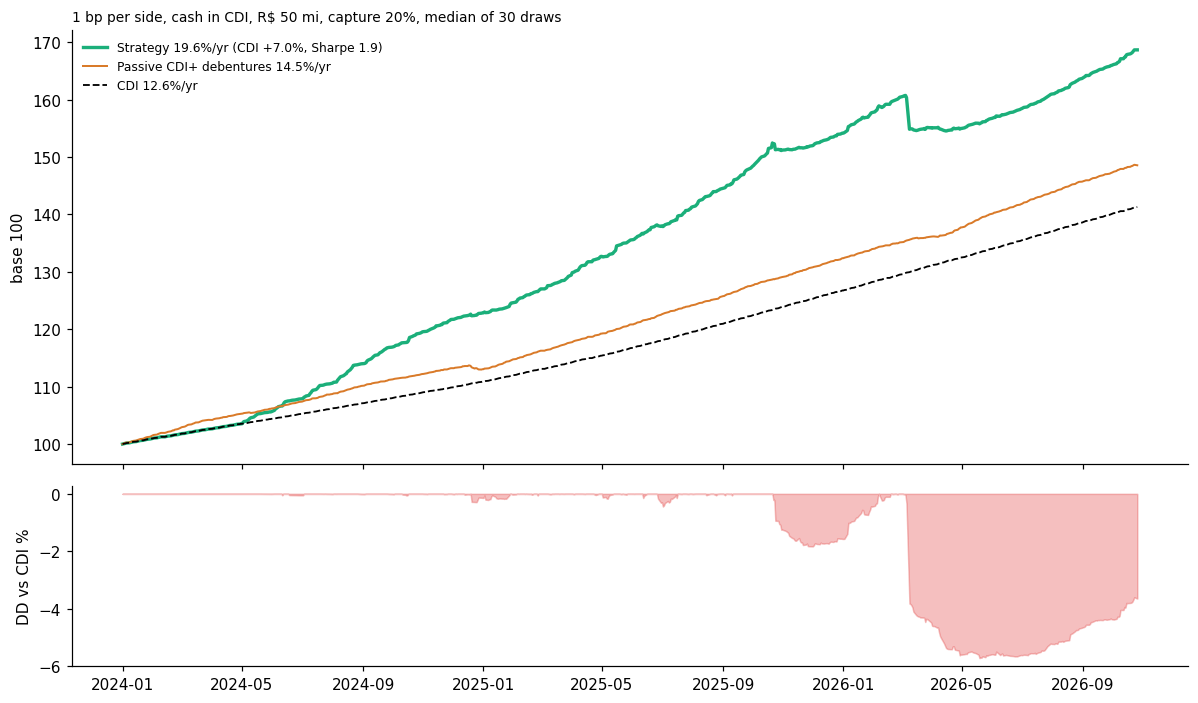

In [6]:
def passive_cdi_plus(days, capital):
    """Benchmark: equal-weight passive CDI+ debentures marked at ANBIMA (price + CDI + spread)."""
    A, B = DATA["A"], DATA["B"]
    A = A[A.code.map(B.indexer) == "CDI+"].sort_values(["code", "date"]).copy()
    A["r"] = A.groupby("code").pct_par.pct_change(fill_method=None); A = A[A.r.abs() < 0.05]
    cdi_d = CDI.pct_change()
    A["tot"] = (1 + A.r) * (1 + A.date.map(cdi_d).fillna(0)) * (1 + A.code.map(B.spread).fillna(0).clip(0, 10) / 100) ** (1 / 252) - 1
    return (1 + A.groupby("date").tot.mean().reindex(days).fillna(0)).cumprod() * capital

BASE, RB = stats(P, draws=30)
print("DEFAULT:", show(BASE))
print("by year:", {k: f"{v:+.2%}" for k, v in BASE["by_year"].items()})
med = RB.sort_values("excess").iloc[len(RB) // 2]
days, eq, cdi_eq = med.curve
pas = passive_cdi_plus(days, CAPITAL)
med.Tr.to_csv(OUT / "trades_median_draw.csv", index=False)
yrs = len(days) / 252; ann = lambda s: (s.iloc[-1] / s.iloc[0]) ** (1 / yrs) - 1
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), dpi=110, gridspec_kw={"height_ratios": [2.4, 1]}, sharex=True)
ax.plot(days, eq / CAPITAL * 100, lw=2.2, color="#1baf7a", label=f"Strategy {ann(eq):.1%}/yr (CDI {BASE['excess']:+.1%}, Sharpe {BASE['sharpe']:.1f})")
ax.plot(days, pas / CAPITAL * 100, lw=1.3, color="#d97a29", label=f"Passive CDI+ debentures {ann(pas):.1%}/yr")
ax.plot(days, cdi_eq / CAPITAL * 100, lw=1.2, ls="--", color="k", label=f"CDI {ann(cdi_eq):.1%}/yr")
ax.set_ylabel("base 100"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title(f"{COST_BPS:g} bp per side, cash in CDI, R$ {CAPITAL / 1e6:.0f} mi, capture {CAPTURE:.0%}, median of 30 draws", loc="left", fontsize=9)
rel = eq / cdi_eq; ax2.fill_between(days, (rel / rel.cummax() - 1) * 100, 0, color="#e34948", alpha=0.35); ax2.set_ylabel("DD vs CDI %")
for a in (ax, ax2): a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "equity_curve.png"); plt.show()

## 9. Robustness analysis
Each variant changes **one** thing from the default and reports the mean over capture draws.

| Block | What changes | Rebuild? |
|---|---|---|
| A | Book: cut, capture, cost, bond cap, distressed cap / threshold, fund size | No |
| B | Dump definition: min / max discount, min print size (model refit) | No (subset of the loose build) |
| C | Holding period 10 / 42 bd | Yes |
| D | Lag test: features from t−2 | Yes |
| E | Model: tree settings, seeds, feature subsets, no model at all | No |
| F | Time: by year, by half, later out-of-sample start | No |
| G | Bootstrap of monthly excess | No |

**What we found (run on 04/11/2026):**
- **Holds up:**
  - CDI + positive in **all ~60 variants**;
  - cost 0 → 10 bp per side: +7.2% → +5.9%;
  - lag test +6.9%;
  - seeds 6.7-7.3%;
  - bond cap 2-6% is irrelevant;
  - the distressed limit cuts the worst month −4.0% → −1.6%;
  - bootstrap p5 +3.0%/yr, P(lose to CDI) 0.3%.
- **Weak spots:**
  1. **The edge decays.** First half +11.9%/yr (Sharpe 4.9), second half (from 06/2025) +1.9% (Sharpe 0.5); 2026 ≈ 0.
  2. **The model barely beats "buy every dump"** (+9.7% vs +7.0%: wins 2025, loses 2024).
  3. **Capacity** (R$ 10 / 50 / 200 / 500 mi: +9.4 / +7.0 / +4.7 / +3.0%).
  4. **Profit sits in small prints** (R$ 100k: +9.9%; 1 mi: +3.4%; 3 mi: +0.3%), where the real markup is far above 1 bp.
  5. **Holding period** (10 bd +16%, 21 bd +7%, 42 bd +2.8%): not pre-chosen, so it must be confirmed live.

In [7]:
rows = []
def add(group, name, s, default=False):
    rows.append(dict(group=group, variant=name, default=default, **{k: v for k, v in s.items() if k != "by_year"}))
    print(f"{group:<26} {name:<38} {show(s)}")

add("default", "default (30 draws)", BASE, True)
# A. book parameters
for v in (0.6, 0.65, 0.7, 0.75, 0.8): add("A cut", str(v), stats(P, cut=v)[0], v == CUT)
for v in (0.1, 0.2, 0.33, 0.5, 1.0): add("A capture", f"{v:.0%}", stats(P, capture=v)[0], v == CAPTURE)
for v in (0, 1, 3, 5, 10): add("A cost per side (bps)", str(v), stats(P, cost=v)[0], v == COST_BPS)
for v in (0.02, 0.04, 0.06): add("A bond cap", f"{v:.0%}", stats(P, cap_bond=v)[0], v == CAP_BOND)
for v in (0.0, 0.005, 0.01, 0.02, 0.04): add("A distressed cap", f"{v:.1%}" + (" (skip)" if v == 0 else " (no limit)" if v == 0.04 else ""), stats(P, cap_distress=v)[0], v == CAP_DISTRESS)
for v in (85, 90, 95): add("A distressed threshold", f"< {v}% par", stats(P, distress_pct=v)[0], v == DISTRESS_PCT)
for v in (10e6, 50e6, 200e6, 500e6): add("A fund size", f"R$ {v / 1e6:.0f} mi", stats(P, capital=v)[0], v == CAPITAL)
# B. dump definition (model refit on each)
for v in (30, 50, 100, 200): add("B min discount (bps)", str(v), stats(walk_forward(dumps(Pall, min_disc=v)))[0], v == MIN_DISC)
for v in (500, 1000, 2000, 5000): add("B max discount (bps)", str(v), stats(walk_forward(dumps(Pall, max_disc=v)))[0], v == MAX_DISC)
for v in (1e5, 3e5, 1e6, 3e6): add("B min print size", f"R$ {v / 1e3:.0f}k", stats(walk_forward(dumps(Pall, min_vol=v)))[0], v == MIN_VOL)
# E. model
P0 = dumps(Pall)
for k, vals in (("num_leaves", (7, 31)), ("n_estimators", (150, 600)), ("min_child_samples", (100, 400))):
    for v in vals: add(f"E model {k}", str(v), stats(walk_forward(P0, params={**LGB_PARAMS, k: v}))[0])
for seed in (1, 2, 3, 4): add("E model seed", str(seed), stats(walk_forward(P0, params={**LGB_PARAMS, "random_state": seed}))[0])
for nm, drop in (("without fund stress (CVM)", ["dse"]), ("without intraday (time, n-th dump, lot)", ["hour", "n_prior_today", "round_lot"]),
                 ("without momentum / levels", ["mom5", "mom20", "iss_mom5", "iss_min", "fair"]),
                 ("only the print", [f for f in FEATS if f not in ("disc", "log_vol", "size_adv", "dur", "is_cdi", "is_ipca", "is_pre")])):
    add("E features", nm, stats(walk_forward(P0, feats=[f for f in FEATS if f not in drop]))[0])
add("E no model", "buy every dump (risk limits only)", stats(P.assign(pc=1.0))[0])
# F. time
mm = pd.concat(list(RB.m), axis=1).mean(axis=1); h = len(mm) // 2
for nm, x in (("first half", mm.iloc[:h]), ("second half", mm.iloc[h:])):
    print(f"F {nm} {x.index[0]:%Y-%m}..{x.index[-1]:%Y-%m}: CDI {(1 + x).prod() ** (12 / len(x)) - 1:+.2%}/yr, Sharpe {x.mean() / x.std() * np.sqrt(12):.2f}")
print("F by year:", {k: f"{v:+.2%}" for k, v in BASE["by_year"].items()})
# G. bootstrap
rng = np.random.default_rng(0); bs = [rng.choice(mm.values, len(mm)) for _ in range(5000)]
print(f"G bootstrap: excess p5 {np.percentile([(1 + b).prod() ** (12 / len(b)) - 1 for b in bs], 5):+.2%}/yr, "
      f"Sharpe p5 {np.percentile([b.mean() / b.std() * np.sqrt(12) for b in bs], 5):.2f}, P(lose to CDI) {np.mean([(1 + b).prod() < 1 for b in bs]):.2%}")
# C / D. rebuilds
if RUN_FULL_ROBUSTNESS:
    for v in (10, 42): add("C holding period (bd)", str(v), stats(walk_forward(dumps(build(hold_bd=v))))[0])
    add("D lag test", "features from t-2", stats(walk_forward(dumps(build(lag_bd=2))))[0])
SENS = pd.DataFrame(rows); SENS.to_csv(OUT / "sensitivity.csv", index=False)

default                    default (30 draws)                     CDI +6.96%/yr (p5 +6.20%), Sharpe 1.88, worst month -2.86%, max DD vs CDI -4.85%, 2196 trades, hit 78.4%, capital used 84%


A cut                      0.6                                    CDI +7.22%/yr (p5 +6.09%), Sharpe 1.89, worst month -2.93%, max DD vs CDI -5.46%, 2402 trades, hit 77.7%, capital used 91%


A cut                      0.65                                   CDI +7.43%/yr (p5 +6.64%), Sharpe 2.01, worst month -2.51%, max DD vs CDI -5.22%, 2389 trades, hit 77.7%, capital used 91%


A cut                      0.7                                    CDI +7.03%/yr (p5 +6.22%), Sharpe 1.90, worst month -3.11%, max DD vs CDI -4.92%, 2201 trades, hit 78.4%, capital used 84%


A cut                      0.75                                   CDI +7.95%/yr (p5 +7.62%), Sharpe 2.76, worst month -1.07%, max DD vs CDI -2.20%, 2056 trades, hit 80.6%, capital used 77%


A cut                      0.8                                    CDI +9.00%/yr (p5 +8.47%), Sharpe 3.25, worst month -0.65%, max DD vs CDI -1.47%, 1907 trades, hit 82.9%, capital used 71%


... (52 outputs left out)

G bootstrap: excess p5 +2.99%/yr, Sharpe p5 0.76, P(lose to CDI) 0.28%


C holding period (bd)      10                                     CDI +15.72%/yr (p5 +15.14%), Sharpe 4.00, worst month -1.17%, max DD vs CDI -2.02%, 4002 trades, hit 81.6%, capital used 87%


C holding period (bd)      42                                     CDI +2.58%/yr (p5 +1.98%), Sharpe 1.12, worst month -1.15%, max DD vs CDI -2.78%, 1096 trades, hit 72.9%, capital used 75%


D lag test                 features from t-2                      CDI +7.64%/yr (p5 +7.15%), Sharpe 2.60, worst month -1.20%, max DD vs CDI -2.49%, 2162 trades, hit 77.8%, capital used 82%


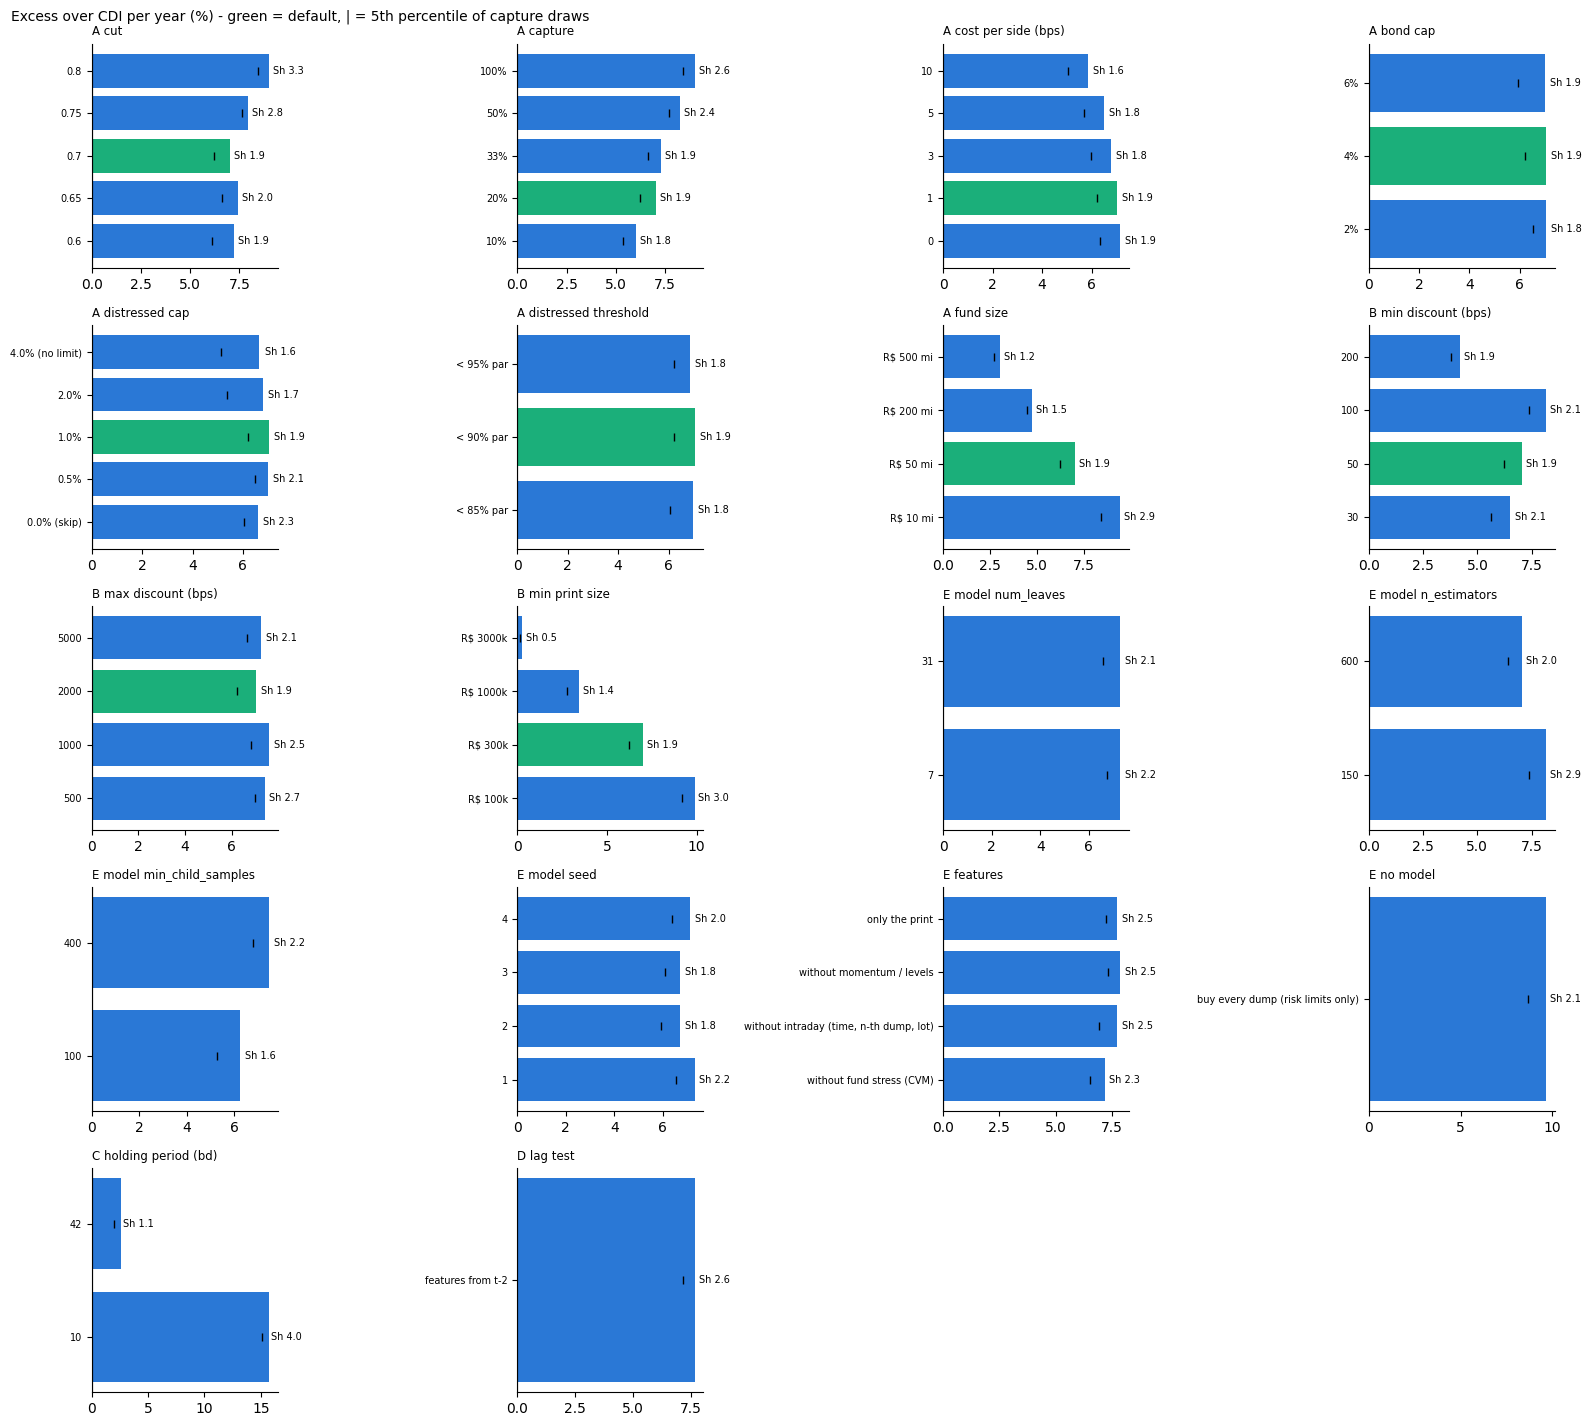

In [8]:
G = [g for g in dict.fromkeys(SENS.group) if g != "default"]
fig, axs = plt.subplots(int(np.ceil(len(G) / 4)), 4, figsize=(16, 2.9 * int(np.ceil(len(G) / 4))), dpi=100); axs = axs.ravel()
for ax, g in zip(axs, G):
    d = SENS[SENS.group == g]
    ax.barh(range(len(d)), d.excess * 100, color=["#1baf7a" if x else "#2a78d6" for x in d.default])
    ax.errorbar(d.excess_p5 * 100, range(len(d)), fmt="|", color="k")
    for i, (e, sh) in enumerate(zip(d.excess, d.sharpe)): ax.text(max(e * 100, 0) + 0.2, i, f"Sh {sh:.1f}", va="center", fontsize=7)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.variant, fontsize=7); ax.axvline(0, color="k", lw=0.8)
    ax.set_title(g, fontsize=8.5, loc="left"); ax.spines[["top", "right"]].set_visible(False)
for ax in axs[len(G):]: ax.axis("off")
fig.suptitle("Excess over CDI per year (%) - green = default, | = 5th percentile of capture draws", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "sensitivity.png"); plt.show()

## 10. Scaling

**The binding constraint is flow, not capital.** We can only buy what sellers dump. The average inventory we can hold is roughly the monthly dump volume we capture × the holding period. The cells below measure:
1. how much model-approved dump volume the market produces;
2. where the return sits by lot size;
3. what a **block sleeve** does (bigger limits for dumps ≥ R$ 3 mi, optionally with its own model), across fund size × capture.

**Levers, in order of impact:**
1. **Capture more flow**, the biggest lever:
   - be on dealers' RFQ lists and the electronic platforms;
   - get the flow the house's own desks see;
   - cross-trade with the house's funds facing redemptions (compliance: fair price, cross-trade rules).

   At 50% capture the inventory capacity is ≈ R$ 1 bn.
2. **A block sleeve.** Measured below: dumps **> R$ 10 mi are 65% of the volume at +83 bps per trade** (3-10 mi: 15% at +21; 1-3 mi: 9% at −27; < 1 mi: 11% at +84). The very large blocks are the scalable pool.

   **Results of the test below (run 04/11/2026):** a separate block model with an 8% cap helps at R$ 50 mi (CDI +7.8% vs +7.1%, Sharpe 2.5 vs 2.0). It **hurts** at R$ 200 mi - 1 bn: that model is too strict and leaves 50-90% of capital idle. With one model and 4% caps, CDI + falls from +7% (R$ 50 mi) to +4.7% (200 mi), +3.1% (500 mi) and +1.9% (1 bn) at 20% capture, or +5.9 / +5.2 / +3.7% at 50% capture. In R$, the excess P&L keeps growing up to ~R$ 500 mi (≈ R$ 26 mi / yr at 50% capture). **Next step for scale:** a block sleeve that keeps the main model's selection, sizes up only for > R$ 10 mi dumps, and is sized in R$ (not % of the fund).
3. **Exit into buyers** (funds with inflows, distribution platforms) instead of waiting 21 bd. This earns the spread on both sides and recycles capital (most of the reversion happens in ~10 bd).
4. **More instruments with the same mechanics:** CRI, CRA, Letras Financeiras, FIDC seniors, listed FI-Infra quotas. Set `SQL["trades_types"]` once marks for them exist (§ 11).
5. **Capital efficiency:** hedge with DI1 / DAP futures instead of Tesouro, and fund inventory in repo. This raises return on capital, not capacity.
6. **Lean into stress windows:** margins are highest 20-90 bd after a credit-fund stress episode begins.

**Two warnings:**
- The edge has shrunk since mid-2025. Find out whether that is competition (permanent) or 2026's credit stress (temporary) before scaling.
- At 50%+ capture you set the dump prices yourself, and the discount shrinks. Only live trading measures this.

In [9]:
Q = P[(P.date >= OOS_START) & (P.pc >= CUT)].copy()
mv = Q.groupby(Q.date.dt.to_period("M")).vol.sum() / 1e6
print(f"model-approved dump volume: median R$ {mv.median():,.0f} mi/month (p25 {mv.quantile(.25):,.0f}, p75 {mv.quantile(.75):,.0f})")
for cap_ in (0.2, 0.5, 1.0):
    print(f"  capture {cap_:.0%}: average inventory ~ R$ {mv.median() * cap_ * HOLD_BD / 21:,.0f} mi (hold {HOLD_BD} bd)")
Q["bucket"] = pd.cut(Q.vol, [0, 1e6, 3e6, 1e7, 1e12], labels=["< 1 mi", "1-3 mi", "3-10 mi", "> 10 mi"])
tab = Q.groupby("bucket", observed=True).agg(dumps=("ret", "size"), volume_share=("vol", "sum"), mean_bps=("ret", lambda s: s.mean() * 1e4),
                                             hit=("y", "mean"))
tab["volume_share"] = tab.volume_share / tab.volume_share.sum()
print(tab.round(3))
print("measured round-trip dealer markup by size (bps, mean): <100k 178 | 100-300k 146 | 300k-1m 60 | 1-3m 20 | 3-10m 10 | >10m 7")

model-approved dump volume: median R$ 2,018 mi/month (p25 1,267, p75 3,066)
  capture 20%: average inventory ~ R$ 404 mi (hold 21 bd)
  capture 50%: average inventory ~ R$ 1,009 mi (hold 21 bd)
  capture 100%: average inventory ~ R$ 2,018 mi (hold 21 bd)
         dumps  volume_share  mean_bps    hit
bucket                                       
< 1 mi   16826         0.109    84.076  0.731
1-3 mi    4550         0.092   -27.445  0.614
3-10 mi   2112         0.150    20.864  0.632
> 10 mi   1442         0.649    82.921  0.705
measured round-trip dealer markup by size (bps, mean): <100k 178 | 100-300k 146 | 300k-1m 60 | 1-3m 20 | 3-10m 10 | >10m 7


R$    50 mi | capture 20% | default (one model, 4% cap)                        CDI +7.05%/yr (p5 +6.40%), Sharpe 1.98, worst month -2.70%, max DD vs CDI -4.98%, 2190 trades, hit 78.4%, capital used 83%


R$    50 mi | capture 20% | block sleeve (separate model, 8% cap for >= 3 mi)  CDI +7.77%/yr (p5 +6.53%), Sharpe 2.50, worst month -1.76%, max DD vs CDI -2.88%, 2514 trades, hit 78.6%, capital used 85%


R$    50 mi | capture 50% | default (one model, 4% cap)                        CDI +8.09%/yr (p5 +7.63%), Sharpe 2.15, worst month -2.37%, max DD vs CDI -4.57%, 2435 trades, hit 79.0%, capital used 90%


R$    50 mi | capture 50% | block sleeve (separate model, 8% cap for >= 3 mi)  CDI +8.68%/yr (p5 +7.96%), Sharpe 2.58, worst month -1.95%, max DD vs CDI -2.95%, 2744 trades, hit 80.3%, capital used 91%


R$   200 mi | capture 20% | default (one model, 4% cap)                        CDI +4.69%/yr (p5 +4.53%), Sharpe 1.42, worst month -2.28%, max DD vs CDI -4.69%, 3757 trades, hit 76.8%, capital used 67%


R$   200 mi | capture 20% | block sleeve (separate model, 8% cap for >= 3 mi)  CDI +3.00%/yr (p5 +2.53%), Sharpe 1.44, worst month -1.68%, max DD vs CDI -3.39%, 4103 trades, hit 74.5%, capital used 49%


... (6 outputs left out)

R$  1000 mi | capture 20% | default (one model, 4% cap)                        CDI +1.92%/yr (p5 +1.74%), Sharpe 1.19, worst month -1.19%, max DD vs CDI -2.71%, 4988 trades, hit 71.2%, capital used 32%


R$  1000 mi | capture 20% | block sleeve (separate model, 8% cap for >= 3 mi)  CDI +0.55%/yr (p5 +0.41%), Sharpe 1.00, worst month -0.58%, max DD vs CDI -1.17%, 4308 trades, hit 73.2%, capital used 12%


R$  1000 mi | capture 50% | default (one model, 4% cap)                        CDI +3.68%/yr (p5 +3.23%), Sharpe 1.10, worst month -3.11%, max DD vs CDI -4.97%, 10045 trades, hit 75.5%, capital used 59%


R$  1000 mi | capture 50% | block sleeve (separate model, 8% cap for >= 3 mi)  CDI +1.28%/yr (p5 +1.13%), Sharpe 0.93, worst month -1.33%, max DD vs CDI -2.64%, 10210 trades, hit 73.5%, capital used 28%


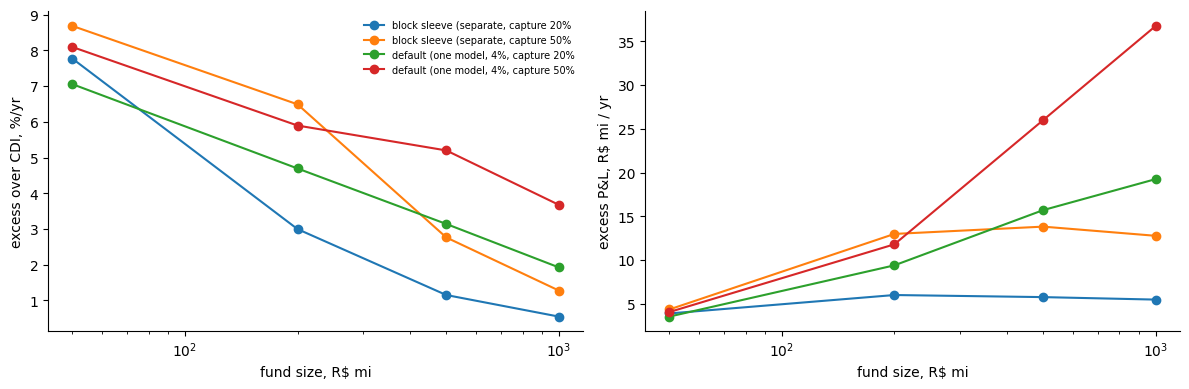

In [10]:
# block sleeve: separate model trained only on blocks + bigger cap for blocks, vs the default, across fund size x capture
Pblk = walk_forward(P0[P0.vol >= BLOCK_MIN]); Psml = walk_forward(P0[P0.vol < BLOCK_MIN])
Psplit = pd.concat([Pblk, Psml]).sort_values("date").reset_index(drop=True)
scal = []
for capital in (50e6, 200e6, 500e6, 1000e6):
    for capture in (0.2, 0.5):
        for nm, PP, cb in (("default (one model, 4% cap)", P, None), ("block sleeve (separate model, 8% cap for >= 3 mi)", Psplit, 0.08)):
            s = stats(PP, draws=5, capital=capital, capture=capture, cap_block=cb)[0]
            scal.append(dict(capital=capital / 1e6, capture=capture, version=nm, excess=s["excess"], sharpe=s["sharpe"], worst=s["worst_month"],
                             capital_used=s["capital_used"], pnl_mi_per_yr=s["excess"] * capital / 1e6))
            print(f"R$ {capital / 1e6:>5.0f} mi | capture {capture:.0%} | {nm:<50} {show(s)}")
SCAL = pd.DataFrame(scal); SCAL.to_csv(OUT / "scaling.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), dpi=100)
for (nm, cap_), d in SCAL.groupby(["version", "capture"]):
    ax[0].plot(d.capital, d.excess * 100, marker="o", label=f"{nm[:22]}, capture {cap_:.0%}")
    ax[1].plot(d.capital, d.pnl_mi_per_yr, marker="o", label=f"{nm[:22]}, capture {cap_:.0%}")
ax[0].set_xscale("log"); ax[1].set_xscale("log"); ax[0].set_xlabel("fund size, R$ mi"); ax[1].set_xlabel("fund size, R$ mi")
ax[0].set_ylabel("excess over CDI, %/yr"); ax[1].set_ylabel("excess P&L, R$ mi / yr"); ax[0].legend(fontsize=7, frameon=False)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / "scaling.png"); plt.show()

## 11. Live test: what to pull from SQL, daily routine, go / no-go

### 11.1 Data to pull from SQL (everything needed)
Every query is date-limited (one month per query for history; D-1 for the daily refresh).

| # | Data | Table (known) / what to ask for | Columns | History | Refresh | Check |
|---|---|---|---|---|---|---|
| S1 | **B3 secondary trades** (debentures; for scaling also CRI, CRA, LF) | `B3_CREDITO_OPERACOES` | `datanegocio`, **time of trade** (`horanegocio` or equivalent: confirm name), `codigoif`, `instrumentofinanceiro`, `qtdadenegociada`, `preconegocio`, `volumefinanceiro`, `taxanegocio`, `origemnegocio`, trade status / cancellation flag, trade id if any | 2023-04 → today | Daily (D-1); intraday if available | No duplicates; volume = qty × PU; cancelled trades removed; time present |
| S2 | **ANBIMA marks** (all debentures, incl. matured / defaulted) | `tbhh3003_anbima_debenture_mercado_secundario` | `data_referencia`, `codigo_ativo`, `grupo` (indexer), `taxa_indicativa`, `pu`, `percent_pu_par`, `duration` (unit: business days?) | 2022 → today | Daily (published ~evening) | PU par = PU / %PU par is smooth; duration unit confirmed |
| S3 | ANBIMA marks for **CRI / CRA** (scaling) | Ask: is there a CRI/CRA ANBIMA table? | Same as S2 | 2023 → | Daily | Only needed to add those instruments |
| S4 | **Bond master** | Ask: internal debenture master (or keep SND download) | Code, ISIN, issuer CNPJ, indexer, spread / coupon, issue / maturity dates, call clause, incentivized flag, economic group | Current + dead bonds | Weekly | Every traded code mapped |
| S5 | **Payment events and defaults** | Ask: internal SND events / credit events table (or keep SND download) | Code, date, event type, status (paid / not paid) | 2014 → | Daily | Failures flagged the same day |
| S6 | **Rates curves** | Ask: internal DI1 / DAP / NTN-B curves | Date, maturity / vertex, rate | 2022 → | Daily | Replaces the Tesouro CSV; DAP / DI1 are the instruments the hedge will actually use |
| S7 | CDI, IPCA | Any internal market-data table (or BCB API) | Date, value | 2018 → | Daily / monthly | |
| S8 | **Internal fund positions** | `VW_FUNDOS_POSICAO_EXPLODIDA_DOWN` | `date`, `codigo_IAM_fundo`, `codigo_IAM_fundo_origem`, `codigo_IAM_ativo`, `tipo`, `perc_nav`, `isin`, `issuer` | Month-end 2021 → and daily if possible | Daily | Which house funds hold each bond → candidates for internal crosses and their redemption pressure |
| S9 | **House fund flows / redemption schedules** | Ask: daily subscriptions / redemptions and pending redemption requests (D+30 queue) of house credit funds | Fund, date, requested redemption, payment date, NAV | 2023 → | Daily | Gives forced-seller flow **before** it hits the market: the best scaling input |
| S10 | **Desk RFQ / order log** (the most important new data) | Ask: the desk's own RFQ history for debentures (received and answered) | Timestamp, code, side, size, price / rate asked, counterparty type (dealer / fund / broker), our quote, traded (Y/N), traded price, number of competing dealers | As long as kept | Real time | Measures **capture** and real **fill cost**, the two assumptions the backtest cannot test |
| S11 | Desk executions | Ask: executed trades of the desk / fund | Timestamp, code, side, size, price, counterparty, fees | Live test period | Real time | Real cost per lot size vs 1 bp |

The query template is in `load_trades()` / `load_anbima()`. Change `SQL[...]` column names if a table differs.

### 11.2 Daily routine (paper trading first, 3 months)
1. **07:00.** Refresh S1, S2, S5, S6, S7 for D-1 (`DATA = ...`, then `Pall = build()`).
2. **Quarterly** (or after any data fix), retrain: `train_final()` (§ 12). The model only uses dumps whose exit is known.
3. **Before the open**, run `bid_sheet()`. For each bond it gives yesterday's fair value, the price at which a standard R$ 1 mi dump would be bought (p ≥ `CUT`), the maximum size under the limits, and flags (distressed, payment failure, stress window).
4. **During the day:** for every RFQ / dump seen, run `score_rfq(code, pct_or_price, size, time, n_prior_today)` and record it with `log_rfq(...)`: bid or not, price, size, filled or not.
5. **Each evening:** run `update_paper_log()`. It fills in the exit price and the realized hedged return for paper trades whose exit date has arrived.
6. **Monthly:** run the `paper_report()` checks against the go / no-go criteria below.

### 11.3 Pre-registered go / no-go criteria (set before the test, do not change)
After 3 months of paper trading (≥ 60 paper fills):
- realized hit rate ≥ 65% and mean ≥ +40 bps per trade **after real fill cost** (S11);
- measured capture ≥ 10% of model-approved dumps;
- real round-trip cost at R$ 300k-1 mi ≤ 30 bps;
- no month worse than −2% of the paper book;
- the 21 bd and 10 bd exit versions run side by side. Pick the one that wins in paper, not in the backtest.

Go live small (R$ 10-50 mi) only if **all** pass. Review monthly. Stop if 3 consecutive months are below CDI.

## 12. Live tools: final model, bid sheet, RFQ scorer, paper log
- **Final model:** trained on all dumps whose exit is known. The probability calibration comes from the walk-forward out-of-sample predictions above.
- **Features for a live print:** the same definitions as `build()`, computed from data up to yesterday plus what the print itself shows.

In [11]:
import joblib, lightgbm as lgb
from sklearn.isotonic import IsotonicRegression

def train_final(P, asof=None):
    asof = pd.Timestamp(asof or DATA["T"].date.max())
    feats = [f for f in FEATS if f in P]
    tr = P[P.te < asof - pd.offsets.BDay(5)]
    m = lgb.LGBMClassifier(**LGB_PARAMS).fit(tr[feats], tr.y)
    oos = P.dropna(subset=["p"])
    iso = IsotonicRegression(out_of_bounds="clip").fit(oos.p, oos.y)
    joblib.dump({"model": m, "iso": iso, "feats": feats, "asof": asof, "config": {k: globals()[k] for k in ("CUT", "MIN_DISC", "MAX_DISC", "HOLD_BD", "CAP_BOND", "CAP_ISSUER", "CAP_DISTRESS", "DISTRESS_PCT")}},
                OUT / "final_model.joblib")
    print(f"final model trained on {len(tr):,} closed dumps up to {asof.date()} -> {OUT / 'final_model.joblib'}")
    return m, iso, feats

def bond_state(asof=None):
    """per bond, everything known at the open of `asof` (data up to the previous business day)."""
    asof = pd.Timestamp(asof or (DATA["T"].date.max() + pd.offsets.BDay(1)))
    y = asof - pd.offsets.BDay(1)
    A, B, T, E = DATA["A"], DATA["B"], DATA["T"], DATA["E"]
    A = A[A.date <= y].sort_values(["code", "date"]).copy()
    A["mom5"] = A.pct_par - A.groupby("code").pct_par.shift(5); A["mom20"] = A.pct_par - A.groupby("code").pct_par.shift(20)
    last = A.groupby("code").tail(1).set_index("code")
    last = last[last.date >= y - pd.Timedelta(days=7)]
    S = pd.DataFrame({"fair": last.pct_par, "pu_par_last": last.pu_par, "dur": last.dur, "mom5": last.mom5, "mom20": last.mom20})
    S["indexer"], S["root"] = S.index.map(B.indexer), S.index.map(B.root)
    S = S[S.indexer.isin(["CDI+", "%CDI", "IPCA+", "PRE"])]
    iss = last.assign(root=last.index.map(B.root)).groupby("root").agg(iss_mom5=("mom5", "median"), iss_min=("pct_par", "min"))
    S = S.join(iss, on="root")
    Ty = T[(T.date <= y) & (T.date > y - pd.Timedelta(days=95))]
    dv = Ty.groupby(["code", "date"]).vol.sum().reset_index()
    S["adv63"] = dv[dv.date > y - pd.offsets.BDay(63)].groupby("code").vol.sum().reindex(S.index) / 63
    S["last_trade"] = T[T.date <= y].groupby("code").date.max().reindex(S.index)
    F = E[E.failed & (E.date < asof) & (E.date >= asof - pd.Timedelta(days=90))]
    S["fail_bond90"] = S.index.isin(F.code).astype(float)
    S["fail_iss90"] = S.root.isin(F.code.map(B.root)).astype(float)
    st = DATA["stress"]
    ep = st[st <= asof].max() if st is not None and (st <= asof).any() else None
    S["dse"] = float(min(np.busday_count(ep.date(), asof.date()), 999)) if ep is not None else 999.0
    if S["dse"].iloc[0] > 120: S["dse"] = 999.0
    for k, nm in (("CDI+", "is_cdi"), ("IPCA+", "is_ipca"), ("PRE", "is_pre")): S[nm] = (S.indexer == k).astype(float)
    S["state_date"] = asof
    return S

def _features(S, code, pct, size, hhmm="16:30", n_prior_today=0, qty=None):
    r = S.loc[code]
    return pd.DataFrame([{"disc": (r.fair - pct) / r.fair * 1e4, "log_vol": np.log(size), "size_adv": size / r.adv63 if r.adv63 else np.nan,
                          "dur": r.dur, "fair": r.fair, "is_cdi": r.is_cdi, "is_ipca": r.is_ipca, "is_pre": r.is_pre,
                          "days_since": (r.state_date - r.last_trade).days if pd.notna(r.last_trade) else np.nan, "mom5": r.mom5, "mom20": r.mom20,
                          "iss_mom5": r.iss_mom5, "iss_min": r.iss_min, "fail_bond90": r.fail_bond90, "fail_iss90": r.fail_iss90,
                          "hour": int(hhmm[:2]) + int(hhmm[3:5]) / 60, "n_prior_today": n_prior_today,
                          "round_lot": float(qty % 10 == 0) if qty else 1.0, "dse": r.dse}])

def max_size(S, code, capital=None):
    r = S.loc[code]; capital = capital or CAPITAL
    cap = CAP_DISTRESS if (r.fair < DISTRESS_PCT or (pd.notna(r.iss_min) and r.iss_min < DISTRESS_PCT)) else CAP_BOND
    return cap * capital

def score_rfq(code, price, size, hhmm="16:30", n_prior_today=0, qty=None, S=None, price_is_pu=False):
    """Score one incoming dump / RFQ. price = %PU par (or PU with price_is_pu=True)."""
    S = S if S is not None else STATE; MDL = FINAL
    if code not in S.index: return {"code": code, "decision": "NO - no mark yesterday"}
    pct = price / S.loc[code, "pu_par_last"] * 100 if price_is_pu else price
    X = _features(S, code, pct, size, hhmm, n_prior_today, qty)
    p = float(MDL["iso"].predict(MDL["model"].predict_proba(X[MDL["feats"]])[:, 1])[0])
    disc = float(X.disc.iloc[0]); r = S.loc[code]
    ok = (p >= CUT) and MIN_DISC <= disc <= MAX_DISC and r.fail_bond90 == 0 and r.fail_iss90 == 0
    return {"code": code, "fair_pct": round(r.fair, 3), "price_pct": round(pct, 3), "disc_bps": round(disc, 1), "p": round(p, 3),
            "decision": "BUY" if ok else "NO", "max_size": round(min(size, max_size(S, code)), 0), "indexer": r.indexer,
            "hedge": "short Tesouro x beta" if r.indexer in ("IPCA+", "PRE") else "none"}

def bid_sheet(size=1e6, hhmm="16:30", grid=(50, 75, 100, 150, 200, 300, 400, 500, 750, 1000), S=None):
    """For each bond: the smallest discount (bps) at which a standard dump would be bought, and that bid price (%PU par)."""
    S = S if S is not None else STATE; out = []
    for code in S.index:
        r = S.loc[code]
        if r.fail_bond90 or r.fail_iss90 or not np.isfinite(r.fair): continue
        Xg = pd.concat([_features(S, code, r.fair * (1 - g / 1e4), size, hhmm) for g in grid], ignore_index=True)
        p = FINAL["iso"].predict(FINAL["model"].predict_proba(Xg[FINAL["feats"]])[:, 1])
        ok = np.where(p >= CUT)[0]
        g = grid[ok[0]] if len(ok) else np.nan                  # NaN = the model would not buy this bond at any discount today
        out.append({"code": code, "indexer": r.indexer, "fair_pct": round(r.fair, 3), "bid_disc_bps": g,
                    "bid_pct": round(r.fair * (1 - g / 1e4), 3) if len(ok) else np.nan, "p_at_bid": round(float(p[ok[0]]), 3) if len(ok) else np.nan,
                    "best_p": round(float(p.max()), 3), "best_p_disc_bps": grid[int(p.argmax())], "max_size": max_size(S, code),
                    "distressed": r.fair < DISTRESS_PCT, "stress_days": r.dse if r.dse < 999 else None})
    return pd.DataFrame(out).sort_values(["bid_disc_bps", "best_p"], ascending=[True, False])

LOG = OUT / "paper_trade_log.csv"
LOG_COLS = ["logged_at", "date", "time", "code", "side", "size", "price_pct", "fair_pct", "disc_bps", "p", "decision", "our_bid_pct", "filled",
            "fill_price_pct", "counterparty_type", "n_competing", "exit_date", "exit_pct", "ret_hedged", "notes"]

def log_rfq(code, date, hhmm, size, price_pct, decision, p=None, fair_pct=None, our_bid_pct=None, filled=None, fill_price_pct=None,
            counterparty_type=None, n_competing=None, notes=""):
    """Append one RFQ / dump to the paper-trade log (also log the ones we did NOT bid: they measure what we skip)."""
    row = dict(logged_at=pd.Timestamp.now().isoformat(timespec="seconds"), date=str(pd.Timestamp(date).date()), time=hhmm, code=code, side="buy",
               size=size, price_pct=price_pct, fair_pct=fair_pct, disc_bps=(fair_pct - price_pct) / fair_pct * 1e4 if fair_pct else None, p=p,
               decision=decision, our_bid_pct=our_bid_pct, filled=filled, fill_price_pct=fill_price_pct, counterparty_type=counterparty_type,
               n_competing=n_competing, exit_date=None, exit_pct=None, ret_hedged=None, notes=notes)
    pd.DataFrame([row], columns=LOG_COLS).to_csv(LOG, mode="a", header=not LOG.exists(), index=False)

def update_paper_log():
    """Fill exits of filled paper trades: first trade day after date + HOLD_BD (daily VWAP %PU par); hedged return as in build()."""
    if not LOG.exists(): return None
    L = pd.read_csv(LOG); T = DATA["T"]; A = DATA["A"]
    Dly = T.merge(A[["code", "date", "pu_par"]], on=["code", "date"]).assign(pct=lambda d: d.pu / d.pu_par * 100)
    Dly = Dly.groupby(["code", "date"]).apply(lambda g: np.average(g.pct, weights=g.vol), include_groups=False).rename("pct").reset_index()
    for i, r in L[(L.filled == True) & L.exit_date.isna()].iterrows():
        d = Dly[(Dly.code == r.code) & (Dly.date > pd.Timestamp(r.date) + pd.offsets.BDay(HOLD_BD))].sort_values("date")
        if len(d):
            L.loc[i, "exit_date"], L.loc[i, "exit_pct"] = str(d.date.iloc[0].date()), d.pct.iloc[0]
            L.loc[i, "ret_hedged"] = d.pct.iloc[0] / r.fill_price_pct - 1     # %PU par change; add the hedge leg from the desk's hedge P&L
    L.to_csv(LOG, index=False); return L

def paper_report():
    if not LOG.exists(): print("no paper trades yet"); return
    L = pd.read_csv(LOG); f = L[L.filled == True]; c = f.dropna(subset=["ret_hedged"])
    print(f"RFQs logged {len(L)}, model BUY {int((L.decision == 'BUY').sum())}, filled {len(f)} "
          f"(capture of BUY = {len(f) / max((L.decision == 'BUY').sum(), 1):.0%}), closed {len(c)}")
    if len(c): print(f"closed: hit {(c.ret_hedged > 0).mean():.0%}, mean {c.ret_hedged.mean() * 1e4:+.0f} bps, worst {c.ret_hedged.min() * 1e4:+.0f} bps")

m_, iso_, feats_ = train_final(P)
FINAL = {"model": m_, "iso": iso_, "feats": feats_}
STATE = bond_state()
print("bond state as of", STATE.state_date.iloc[0].date(), "|", len(STATE), "bonds with a mark")
sheet = bid_sheet(); sheet.to_csv(OUT / "bid_sheet.csv", index=False)
n_ok = int(sheet.bid_disc_bps.notna().sum())
print(f"bid sheet: {n_ok} of {len(sheet)} bonds would be bought at some discount <= 1000 bps (p >= {CUT}); "
      f"stress days today: {STATE.dse.iloc[0] if STATE.dse.iloc[0] < 999 else 'no episode'}")
print("(none passing = the model says do not bid today, e.g. inside the first ~20 bd of a credit-fund stress episode)" if n_ok == 0 else "")
display(sheet.head(15))
ex = sheet.code.iloc[0] if len(sheet) else STATE.index[0]
print("example RFQ:", score_rfq(ex, STATE.loc[ex, "fair"] * (1 - 150 / 1e4), 1e6, "16:40"))

final model trained on 41,742 closed dumps up to 2026-10-26 -> C:\Users\maxpn\OneDrive\Documents\itau\credit-backtest\simple_model_out\final_model.joblib


bond state as of 2026-10-27 | 1198 bonds with a mark


bid sheet: 0 of 1193 bonds would be bought at some discount <= 1000 bps (p >= 0.7); stress days today: 17.0
(none passing = the model says do not bid today, e.g. inside the first ~20 bd of a credit-fund stress episode)


,code,indexer,fair_pct,bid_disc_bps,bid_pct,p_at_bid,best_p,best_p_disc_bps,max_size,distressed,stress_days
113,BRKPA3,CDI+,100.763,NaN,NaN,NaN,0.699,750,500000.0,False,17.0
219,CGOS15,CDI+,100.612,NaN,NaN,NaN,0.699,750,2000000.0,False,17.0
221,CGOS17,CDI+,100.552,NaN,NaN,NaN,0.699,750,2000000.0,False,17.0
508,ENGIA7,CDI+,101.044,NaN,NaN,NaN,0.699,150,2000000.0,False,17.0
515,ENGIB7,CDI+,102.174,NaN,NaN,NaN,0.699,750,2000000.0,False,17.0
520,ENGIC4,CDI+,99.672,NaN,NaN,NaN,0.699,750,2000000.0,False,17.0
521,ENGIC5,CDI+,102.189,NaN,NaN,NaN,0.699,750,2000000.0,False,17.0
522,ENGIC6,CDI+,100.491,NaN,NaN,NaN,0.699,150,2000000.0,False,17.0
523,ENGIC9,CDI+,101.476,NaN,NaN,NaN,0.699,750,2000000.0,False,17.0
516,ENGIB8,CDI+,102.216,NaN,NaN,NaN,0.683,750,2000000.0,False,17.0


example RFQ: {'code': 'BRKPA3', 'fair_pct': np.float64(100.763), 'price_pct': np.float64(99.252), 'disc_bps': 150.0, 'p': 0.626, 'decision': 'NO', 'max_size': 500000.0, 'indexer': 'CDI+', 'hedge': 'none'}


### Files written to `simple_model_out/`
- `equity_curve.png`, `trades_median_draw.csv`: backtest
- `sensitivity.csv`, `sensitivity.png`: robustness
- `scaling.csv`, `scaling.png`: scaling
- `final_model.joblib`: live model and its config
- `bid_sheet.csv`: today's bid levels
- `paper_trade_log.csv`: the paper-trading log (`log_rfq` → `update_paper_log` → `paper_report`)